In [1]:
import pandas as pd
import glob
import os

In [ ]:
!ls ../data/processed/df_processed/*/123/*/vtt/*

In [ ]:
true_labels = pd.read_csv(' ct_tiktok/data/true_labels.csv') 
id_labels = pd.read_csv(' ct_tiktok/data/id_labels_seeds.csv')

### Load everything and stuff it in a df

In [11]:
file_pattern = '../data/processed/df_processed/*/123/*/vtt/*'

file_paths = glob.glob(file_pattern)

df_list = []

for file_path in file_paths:
    parts = file_path.split(os.sep)

    dataset = parts[4]
    prompt = parts[6]
    filename = parts[-1]
    
    if 'labeled' in filename: continue
    
    model_name = os.path.splitext(filename)[0].rsplit('_', 1)[-1]

    try:
        df = pd.read_csv(file_path)
    except Exception as e:
        print(f"Failed to load {file_path}: {e}")
        continue
        
    df = df.drop(columns=['Unnamed: 0']).rename(columns={df.columns[-1]: 'label'})

    df['dataset'] = dataset
    df['prompt'] = prompt
    df['model'] = model_name
    #df['label'] = df['label'].astype(str).apply(lambda x : abs(int(x[0])) if (len(x) < 2 and x[0]!=' ') else None) #df['label'].astype(str).apply(lambda x : x[0] if x[0]!=' ' else x[1])

    df_list.append(df)

data = pd.concat(df_list, ignore_index=True)
#data = pd.merge(left=data,right=true_labels,left_on='id',right_on='id',how='left')
data = pd.merge(left=data,right=id_labels,left_on='id',right_on='id',how='left')
data['manual_true_label'] = data['manual_true_label'].fillna(0)
#data.dropna(subset='matched_seeds_all',inplace=True)

In [12]:
data

,id,label,dataset,prompt,model,whisper_cc,true_label,makes_sense,video_description,description_no_hashtags,hashtags_as_string,description_filtered,Unnamed: 0,matched_seeds_all,manual_true_label
0,6946325161821883654,0,imbalanced_distant_label,definition_prompt_end,videollama,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,6959579117985549574,0,imbalanced_distant_label,definition_prompt_end,videollama,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53.0,[],1.0
2,6962726236581891333,1,imbalanced_distant_label,definition_prompt_end,videollama,NaN,NaN,NaN,NaN,NaN,NaN,NaN,394.0,['ufo'],1.0
3,6963206490974899461,1,imbalanced_distant_label,definition_prompt_end,videollama,NaN,NaN,NaN,NaN,NaN,NaN,NaN,646.0,['conspiracy'],1.0
4,6965621858536295686,1,imbalanced_distant_label,definition_prompt_end,videollama,NaN,NaN,NaN,NaN,NaN,NaN,NaN,647.0,['ufo'],1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91186,6995913063748685062,-1,final_sample_w_desc_cleaned,sbs_prompt_end,qwen3:32b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,534.0,['conspiracy'],1.0
91187,7294513529678466350,-1,final_sample_w_desc_cleaned,sbs_prompt_end,qwen3:32b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,853.0,"['conspiracy', 'ufo']",1.0
91188,7196368285712010538,-1,final_sample_w_desc_cleaned,sbs_prompt_end,qwen3:32b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1239.0,['conspiracy'],1.0
91189,7165225180065959214,-1,final_sample_w_desc_cleaned,sbs_prompt_end,qwen3:32b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,940.0,[],1.0


In [5]:
data.dataset.unique()

array(['imbalanced_test', 'final_sample_w_desc_cleaned',
       'imbalanced_distant_label'], dtype=object)

In [6]:
data.prompt.unique()

array(['definition_prompt_end', 'sbs_prompt_end', 'simple_prompt_end'],
      dtype=object)

In [7]:
data.model.unique()

array(['gemma', 'gemma3:12b', 'deepseek-r1:32b', 'deepseek-r1:14b',
       'qwen3:32b', 'mistral', 'gemma3:1b', 'qwen3:14b', 'videollama',
       'llama3', 'gemma3:27b'], dtype=object)

In [13]:
admissible_models = ['gemma', 'deepseek-r1:32b', 
       'qwen3:32b', 'mistral', 'videollama',
       'llama3', 'gemma3:27b']
data = data[data.model.isin(admissible_models)]

In [14]:
# 3 datasets, 3 prompts, 7 models (3 from previous work + 3 "large" LLMs + videollama)
data.drop_duplicates(['dataset', 'prompt', 'model']).shape[0] == 3*3*7

True

In [15]:
import queue
def contains_non_binary(input_string):
    for char in str(input_string):
        if char not in ['0', '1']:
            return True
    return False

def extract_first_binary(input_string):
    queue = []
    for char in str(input_string):
        if char in ['0', '1']:
            queue.append(int(char))
    if queue:
        return queue[len(queue)-1]
    else:
        return None

### Recover labels

In [ ]:
data['error'] = data['label'].apply(contains_non_binary)
data['clean'] = data['label'].apply(extract_first_binary)

In [ ]:
data[(data['manual_true_label'] != data['clean']) & (data['model'] == 'videollama')]['id'].unique()

In [ ]:
data['cross_id'] = data['id'].astype(str) + '_' + data['dataset'] + '_' + data['prompt']

In [19]:
df_wide = data.pivot_table(index='cross_id', columns='model', values='clean', aggfunc='any')

In [34]:
from ast import literal_eval
data['matched_seeds_all'] = data['matched_seeds_all'].apply(literal_eval)
data  = data.explode('matched_seeds_all')

In [ ]:
data

In [37]:
acc_seeds = data.groupby(['matched_seeds_all','dataset','prompt','model'])['clean'].mean()

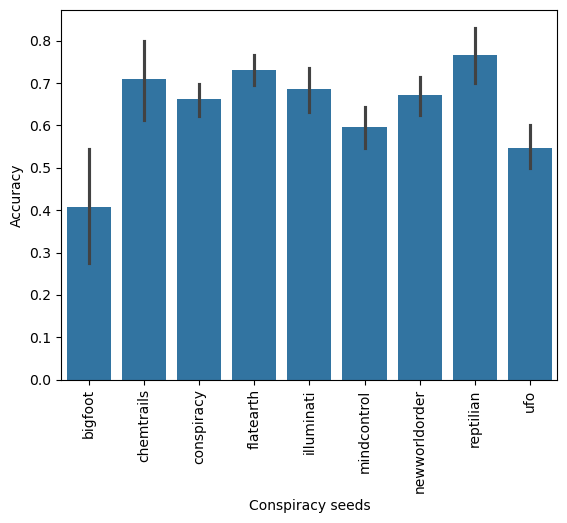

In [ ]:
import seaborn as sns 
import matplotlib.pyplot as plt

sns.barplot(data=pd.DataFrame(acc_seeds),x='matched_seeds_all',y='clean')
plt.xlabel('Conspiracy seeds')
plt.ylabel('Accuracy')
plt.xticks(rotation=90)
plt.savefig(fname=' ct_tiktok/ct_acc.pdf',format='pdf', bbox_inches="tight")

## Precision dividev by CT

### Pairwise Cohen's k

In [37]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score

df_binary = df_wide.dropna().astype(int) # dropping nas!

models = df_binary.columns
models = list(models)

print(models)

kappa_matrix = pd.DataFrame(index=models, columns=models, dtype=float)

for m1 in models:
    for m2 in models:
        if m1 == m2:
            kappa_matrix.loc[m1, m2] = 1.0
        else:
            kappa = cohen_kappa_score(df_binary[m1], df_binary[m2])
            kappa_matrix.loc[m1, m2] = kappa

['deepseek-r1:32b', 'gemma', 'gemma3:27b', 'llama3', 'mistral', 'qwen3:32b', 'videollama']


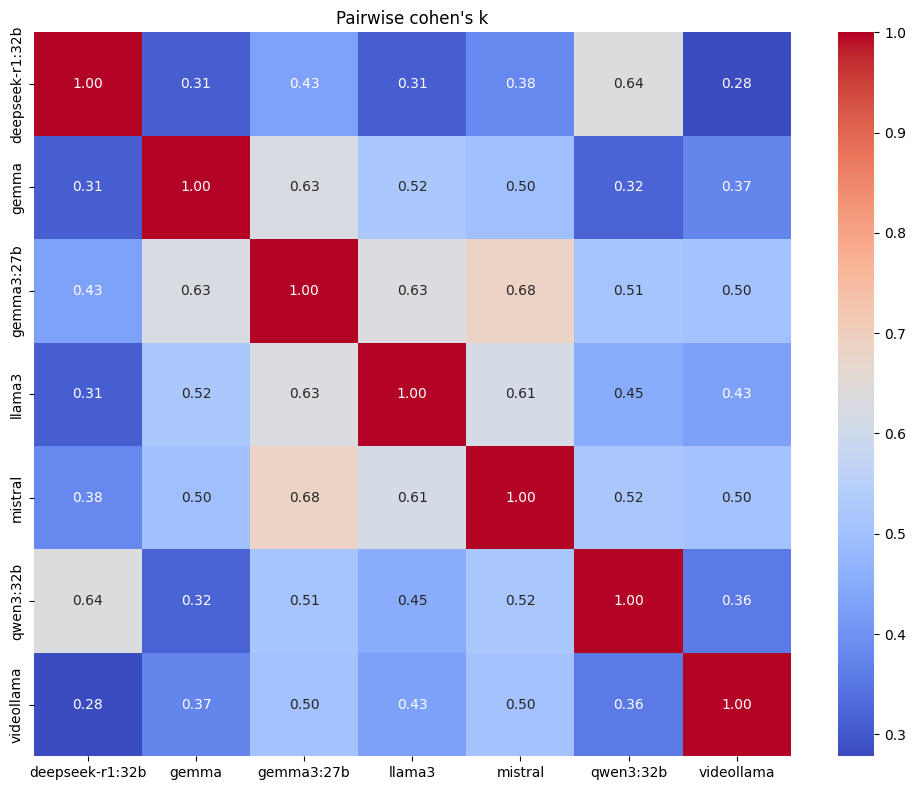

In [38]:
plt.figure(figsize=(10, 8))
sns.heatmap(kappa_matrix.astype(float), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Pairwise cohen's k")
plt.tight_layout()
plt.show()